# Lista de Exercícios 05 – Raízes de Equações – Ponto fixo

## Aluna: Maria Eduarda Saldanha Alves

## 1 - Utilize o método do ponto fixo para encontre a raiz aproximada das seguintes equações. Considere os seguintes pontos:
- Precisão de 6 casas decimais;
- Número máximo de 50 iterações e $\epsilon < 10^{-5}$;
- Isole o intervalo da raiz;
- Analise a convergência do método;
- Apresente o código, solução e passo a passo para chegar nas respostas.

In [1]:
import numpy as np                
import sympy as sy             
import matplotlib.pyplot as plt     
from IPython.display import Math    

x = sy.Symbol('x')                  

def plot(fx, intervalo):
    # np.linspace(a, b) cria 50 pontos igualmente espacados entre a e b
    xx = np.linspace(intervalo[0], intervalo[1])
    plt.plot(xx, fx(xx), label='f(x)')   # desenha a curva: eixo x = xx, eixo y = f(xx)
    plt.grid()                         
    plt.show()                           

def plot3(fx, gx, glx, intervalo):
    xx = np.linspace(intervalo[0], intervalo[1])
    plt.plot(xx, fx(xx), label='f(x)')
    plt.plot(xx, gx(xx), label='g(x)')
    plt.plot(xx, glx(xx), label="g'(x)")
    plt.plot(xx, xx, '--', label='y = x')   # reta y = x: o ponto fixo e onde g(x) cruza essa reta
    plt.legend()                            
    plt.grid()
    plt.show()

def valor_maximo(fx, intervalo):
    # testa 1000 pontos do intervalo e pega o maior |valor| (e o que a condicao 2 pede)
    xx = np.linspace(intervalo[0], intervalo[1], 1000)
    return np.max(np.abs(fx(xx)))           # np.abs = modulo, np.max = maior valor do vetor

def ponto_fixo(gx, fx, intervalo, tol=1e-5, n=50):
    a, b = intervalo
    xk = (a + b) / 2        # primeiro x = ponto medio do intervalo
    xant = np.nan           # x da iteracao anterior (nan = "ainda nao existe")
    dentro = True           # condicao 3: sera que todos os x ficam dentro do intervalo?
    print('k, x, g(x), erro, f(x)')
    for k in range(1, n + 1):
        xk = gx(xk)                              # a iteracao do ponto fixo: x(k+1) = g(x(k))
        erro = abs((xk - xant) / max(xk, 1))     # erro relativo entre x novo e x anterior
                                                 # max(xk, 1) evita dividir por numero muito pequeno
        xant = xk
        if xk < a or xk > b:                     # saiu do intervalo? entao condicao 3 falha
            dentro = False
        print(f'{k}, {xk:.6f}, {gx(xk):.6f}, {erro:.6f}, {fx(xk):.6f}')   
        if fx(xk) == 0 or erro < tol:            # criterio de parada: achou a raiz ou erro < 1e-5
            break
    print(f'Raiz aproximada: {xk:.6f} (iteracoes: {k})')
    print('Todos os x ficaram dentro do intervalo?', 'Sim' if dentro else 'Nao')
    return xk

### a) $f(x) = (x + 0.5)^3 \times e^{(2 - x^2)}$

<IPython.core.display.Math object>

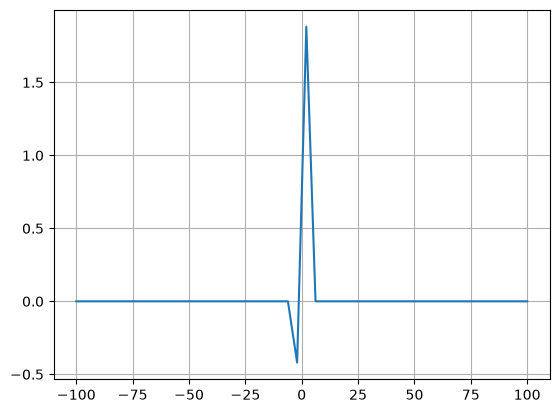

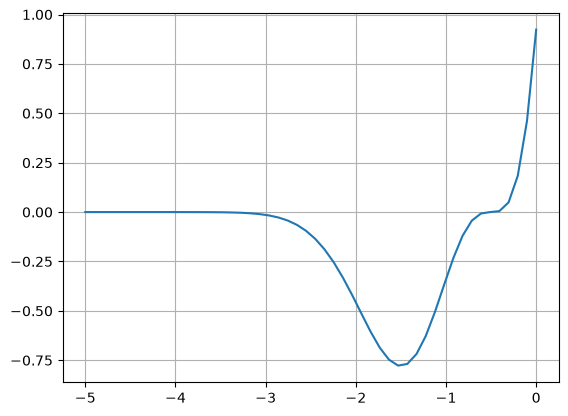

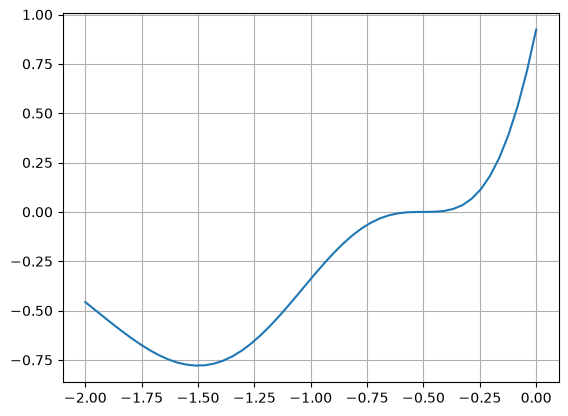

In [2]:
# 1) isolar a raiz: plota em intervalos cada vez menores ate ver so uma raiz
fx_ = (x + 0.5)**3 * sy.exp(2 - x**2)       
display(Math('f(x) = ' + sy.latex(fx_)))    # sy.latex converte a formula pra latex
fx = sy.lambdify(x, fx_)                    # lambdify transforma a formula do sympy numa funcao normal
                                            # do python, que aceita numeros e vetores
plot(fx, [-100, 100])
plot(fx, [-5, 0])
plot(fx, [-2, 0])
intervalo = [-2, 0]

<IPython.core.display.Math object>

<IPython.core.display.Math object>

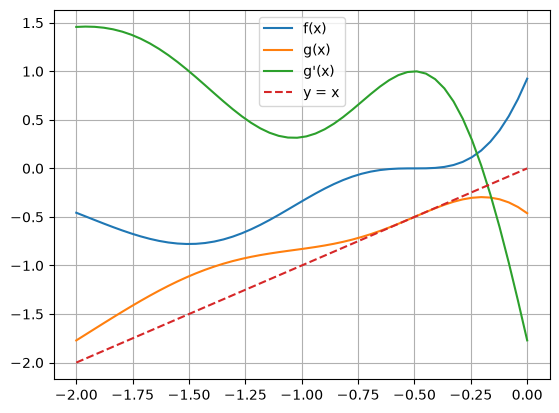

max|g'(x)| = 1.7708960370989937


In [3]:
# 2) escolher g(x) = x - alfa*f(x)
# por que funciona? se f(x) = 0, entao g(x) = x - alfa*0 = x, ou seja, a raiz de f e ponto fixo de g
alfa = 0.5
gx_ = x - alfa * fx_
glx_ = sy.diff(gx_, x)                      # sy.diff(expr, x) = derivada de expr em relacao a x
display(Math('g(x) = ' + sy.latex(gx_)))
display(Math("g'(x) = " + sy.latex(glx_)))
gx = sy.lambdify(x, gx_)
glx = sy.lambdify(x, glx_)
plot3(fx, gx, glx, intervalo)
print("max|g'(x)| =", valor_maximo(glx, intervalo))

In [4]:
# 3) teste de convergencia (teorema do ponto fixo)
# condicao 1) g(x) e g'(x) sao continuas em [-2, 0]? sim (so tem exp e polinomio)
# condicao 2) max|g'(x)| < 1? nao (deu 1.77), entao a condicao falha
# condicao 3) os x ficam dentro do intervalo? a propria funcao ponto_fixo mostra no final
raiz = ponto_fixo(gx, fx, intervalo)

k, x, g(x), erro, f(x)
1, -0.830107, -0.763387, nan, -0.133442
2, -0.763387, -0.725694, 0.066721, -0.075384
3, -0.725694, -0.700610, 0.037692, -0.050169
4, -0.700610, -0.682352, 0.025085, -0.036515
5, -0.682352, -0.668289, 0.018257, -0.028126
6, -0.668289, -0.657023, 0.014063, -0.022532
7, -0.657023, -0.647734, 0.011266, -0.018578
8, -0.647734, -0.639904, 0.009289, -0.015661
9, -0.639904, -0.633186, 0.007830, -0.013435
10, -0.633186, -0.627341, 0.006718, -0.011691
11, -0.627341, -0.622194, 0.005845, -0.010294
12, -0.622194, -0.617617, 0.005147, -0.009154
13, -0.617617, -0.613512, 0.004577, -0.008210
14, -0.613512, -0.609803, 0.004105, -0.007417
15, -0.609803, -0.606431, 0.003709, -0.006744
16, -0.606431, -0.603348, 0.003372, -0.006167
17, -0.603348, -0.600514, 0.003084, -0.005668
18, -0.600514, -0.597898, 0.002834, -0.005232
19, -0.597898, -0.595473, 0.002616, -0.004849
20, -0.595473, -0.593218, 0.002425, -0.004511
21, -0.593218, -0.591113, 0.002255, -0.004210
22, -0.591113, -0.589143,

In [ ]:
# conclusao: x = -0.5 e raiz multipla (o fator (x + 0.5) esta elevado ao cubo),
# entao f'(-0.5) = 0 e g'(-0.5) = 1 - alfa*0 = 1, nunca fica menor que 1.
# o metodo anda em direcao a raiz, mas muito devagar e nao chega em 50 iteracoes

### b) $f(x) = x^3 \times \cos{(x)}$

<IPython.core.display.Math object>

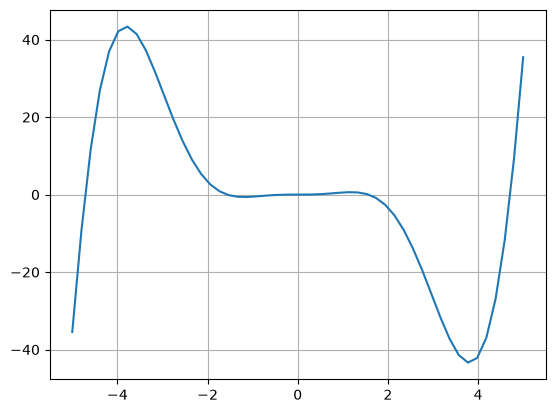

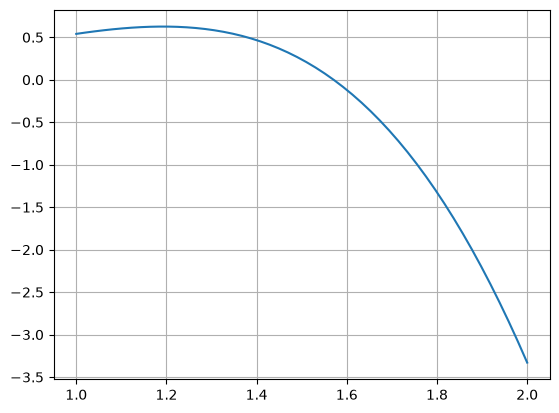

In [6]:
fx_ = x**3 * sy.cos(x)
display(Math('f(x) = ' + sy.latex(fx_)))
fx = sy.lambdify(x, fx_)
plot(fx, [-5, 5])
plot(fx, [1, 2])        # raiz perto de 1.57 (pi/2, onde cos(x) = 0)
intervalo = [1.4, 1.7]  # tentei [1, 2] antes, mas max|g'| passou de 1, entao estreitei

<IPython.core.display.Math object>

<IPython.core.display.Math object>

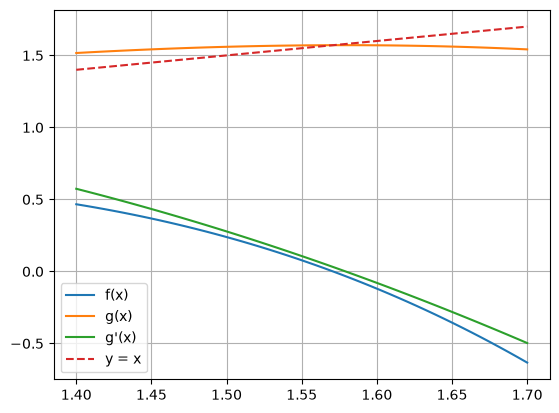

max|g'(x)| = 0.5738331852912708
k, x, g(x), erro, f(x)
1, 1.569359, 1.570748, nan, 0.005554
2, 1.570748, 1.570795, 0.000884, 0.000188
3, 1.570795, 1.570796, 0.000030, 0.000006
4, 1.570796, 1.570796, 0.000001, 0.000000
Raiz aproximada: 1.570796 (iteracoes: 4)
Todos os x ficaram dentro do intervalo? Sim


In [7]:
# f e decrescente perto da raiz (f' negativa), entao alfa negativo deixa g' perto de zero
alfa = -0.25
gx_ = x - alfa * fx_
glx_ = sy.diff(gx_, x)
display(Math('g(x) = ' + sy.latex(gx_)))
display(Math("g'(x) = " + sy.latex(glx_)))
gx = sy.lambdify(x, gx_)
glx = sy.lambdify(x, glx_)
plot3(fx, gx, glx, intervalo)
print("max|g'(x)| =", valor_maximo(glx, intervalo))
raiz = ponto_fixo(gx, fx, intervalo)

In [8]:
# conclusao: converge. max|g'(x)| = 0.57 (< 1) e os x ficam no intervalo.
# raiz aproximada = 1.570796 (pi/2) em 4 iteracoes

### c) $f(x) = 2x^5 - 20x^4 + 5x^3 + x - 1$

<IPython.core.display.Math object>

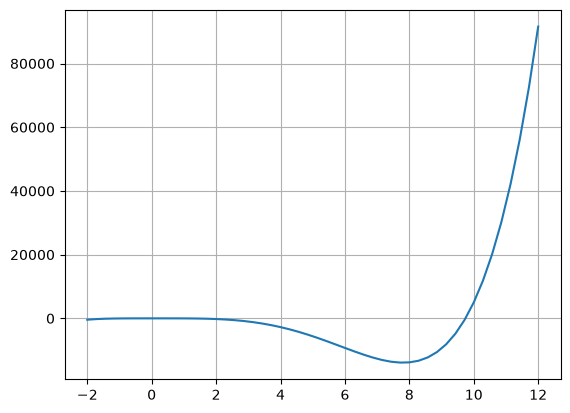

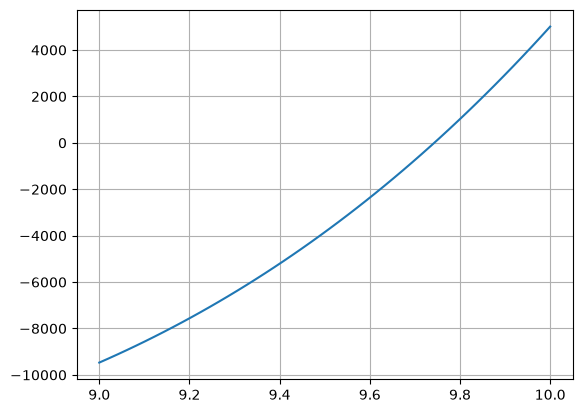

In [9]:
fx_ = 2*x**5 - 20*x**4 + 5*x**3 + x - 1
display(Math('f(x) = ' + sy.latex(fx_)))
fx = sy.lambdify(x, fx_)
plot(fx, [-2, 12])      # so cruza o zero perto de 9.7 (e a unica raiz real)
plot(fx, [9, 10])
intervalo = [9.5, 10]

<IPython.core.display.Math object>

<IPython.core.display.Math object>

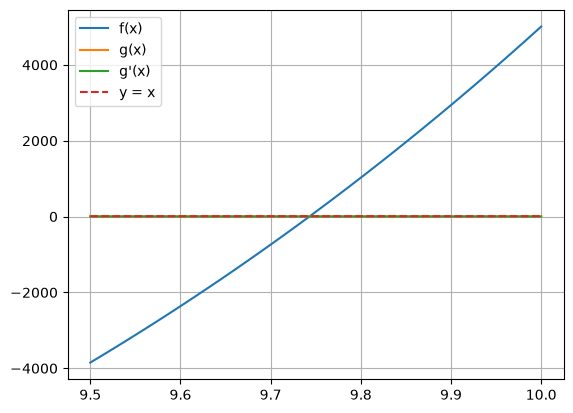

max|g'(x)| = 0.28923125000000005
k, x, g(x), erro, f(x)
1, 9.743770, 9.743023, nan, 14.942371
2, 9.743023, 9.742931, 0.000077, 1.829675
3, 9.742931, 9.742920, 0.000009, 0.224598
Raiz aproximada: 9.742931 (iteracoes: 3)
Todos os x ficaram dentro do intervalo? Sim


In [10]:
# f cresce muito rapido aqui (f' e grande), entao alfa tem que ser bem pequeno
# senao g' fica enorme: g' = 1 - alfa*f'
alfa = 0.00005
gx_ = x - alfa * fx_
glx_ = sy.diff(gx_, x)
display(Math('g(x) = ' + sy.latex(gx_)))
display(Math("g'(x) = " + sy.latex(glx_)))
gx = sy.lambdify(x, gx_)
glx = sy.lambdify(x, glx_)
plot3(fx, gx, glx, intervalo)
print("max|g'(x)| =", valor_maximo(glx, intervalo))
raiz = ponto_fixo(gx, fx, intervalo)

In [11]:
# conclusao: converge. max|g'(x)| = 0.29 (< 1) e os x ficam no intervalo.
# raiz aproximada = 9.742931 em 3 iteracoes (unica raiz real)

### d) $f(x) = \dfrac{1}{2} \sin(x^2) \cos(x)$

<IPython.core.display.Math object>

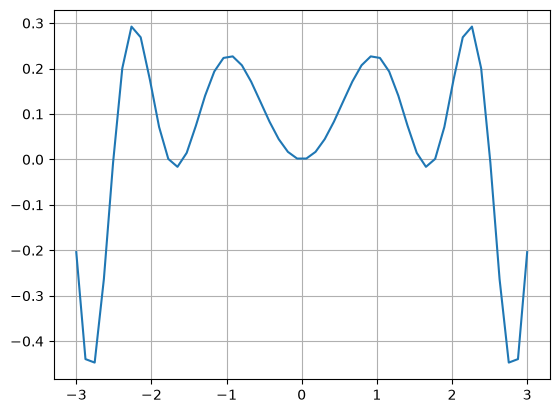

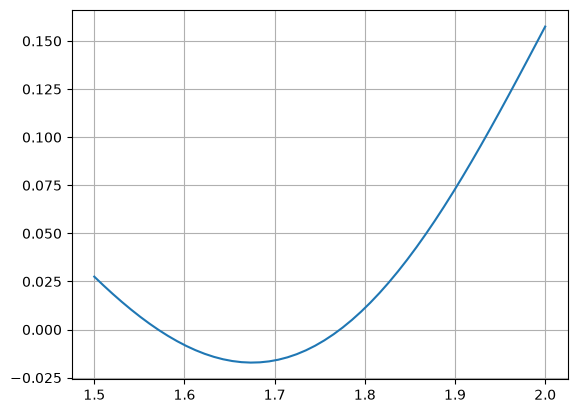

In [12]:
fx_ = sy.Rational(1, 2) * sy.sin(x**2) * sy.cos(x)   # Rational = fracao exata 1/2
display(Math('f(x) = ' + sy.latex(fx_)))
fx = sy.lambdify(x, fx_)
plot(fx, [-3, 3])
plot(fx, [1.5, 2])
intervalo = [1.7, 1.85]

<IPython.core.display.Math object>

<IPython.core.display.Math object>

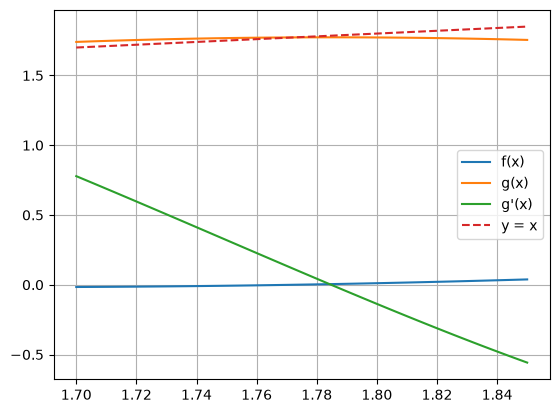

max|g'(x)| = 0.7782402669971428
k, x, g(x), erro, f(x)
1, 1.772710, 1.772482, nan, 0.000091
2, 1.772482, 1.772457, 0.000129, 0.000010
3, 1.772457, 1.772454, 0.000014, 0.000001
4, 1.772454, 1.772454, 0.000002, 0.000000
Raiz aproximada: 1.772454 (iteracoes: 4)
Todos os x ficaram dentro do intervalo? Sim


In [13]:
alfa = 2.5
gx_ = x - alfa * fx_
glx_ = sy.diff(gx_, x)
display(Math('g(x) = ' + sy.latex(gx_)))
display(Math("g'(x) = " + sy.latex(glx_)))
gx = sy.lambdify(x, gx_)
glx = sy.lambdify(x, glx_)
plot3(fx, gx, glx, intervalo)
print("max|g'(x)| =", valor_maximo(glx, intervalo))
raiz = ponto_fixo(gx, fx, intervalo)

In [14]:
# conclusao: converge. max|g'(x)| = 0.78 (< 1) e os x ficam no intervalo.
# raiz aproximada = 1.772454 em 4 iteracoes

### e) $f(x) = \frac{(2x^3 - 4x + 1) \times \sin(x)}{x^2 + 1}$

<IPython.core.display.Math object>

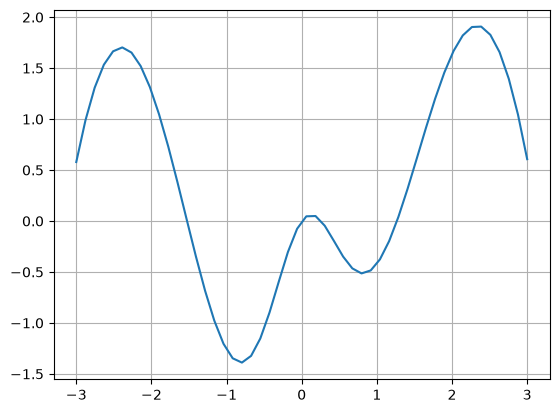

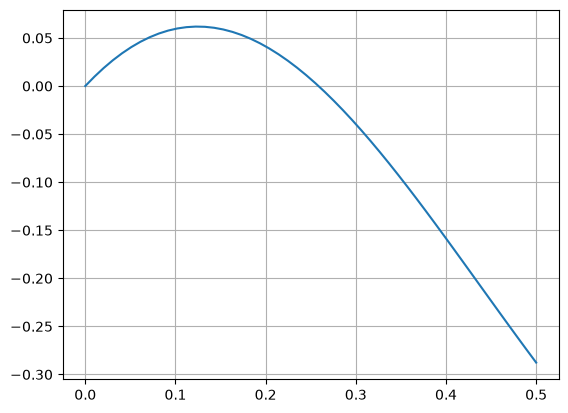

In [15]:
fx_ = (2*x**3 - 4*x + 1) * sy.sin(x) / (x**2 + 1)
display(Math('f(x) = ' + sy.latex(fx_)))
fx = sy.lambdify(x, fx_)
plot(fx, [-3, 3])
plot(fx, [0, 0.5])
intervalo = [0.2, 0.3]

<IPython.core.display.Math object>

<IPython.core.display.Math object>

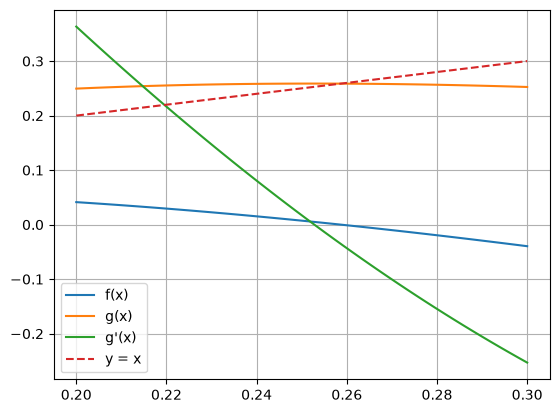

max|g'(x)| = 0.363299454206238
k, x, g(x), erro, f(x)
1, 0.258732, 0.258649, nan, -0.000069
2, 0.258649, 0.258652, 0.000083, 0.000002
3, 0.258652, 0.258652, 0.000003, -0.000000
Raiz aproximada: 0.258652 (iteracoes: 3)
Todos os x ficaram dentro do intervalo? Sim


In [16]:
alfa = -1.2
gx_ = x - alfa * fx_
glx_ = sy.diff(gx_, x)
display(Math('g(x) = ' + sy.latex(gx_)))
display(Math("g'(x) = " + sy.latex(glx_)))
gx = sy.lambdify(x, gx_)
glx = sy.lambdify(x, glx_)
plot3(fx, gx, glx, intervalo)
print("max|g'(x)| =", valor_maximo(glx, intervalo))
raiz = ponto_fixo(gx, fx, intervalo)

In [17]:
# conclusao: converge. max|g'(x)| = 0.36 (< 1) e os x ficam no intervalo.
# raiz aproximada = 0.258652 em 3 iteracoes